In [4]:
import torch
import os
import glob
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- IMPOSTAZIONE DEL DEVICE (GPU o CPU) ---
# Questa cella definisce il device una volta per tutte.
# Tutte le altre parti del codice useranno questa variabile.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in uso: {device}")


print(f"Current working directory: {os.getcwd()}")

COLAB = False;
if COLAB:
    # Montiamo Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # Definiamo il percorso principale
    DATASET_PATH = "/content/drive/MyDrive/Uni/Magistrale/colab/1/ML/Project/training/train"
else:
    DATASET_PATH = "../../dataset/training/train"

# Se si vuole eseguire tutto solo nel main
EXECUTE_MAIN = False;
NUM_WORKERS = 0

Device in uso: cpu
Current working directory: c:\Users\Altair\Documents\GitHub\autoencoder-onboard-segmentation\notebooks\1 - Bilanciamento


In [5]:
# --- DEFINIZIONE DELLA CLASSE DATASET ---
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

class SegmentationDataset(Dataset):
    """
    Versione definitiva e semplificata del Dataset.
    Legge le immagini e le maschere che contengono già gli ID di classe.
    """
    def __init__(self, sample_dirs, transform=None):
        self.sample_dirs = sample_dirs
        self.transform = transform

    def __len__(self):
        return len(self.sample_dirs)

    def __getitem__(self, idx):
        sample_dir = self.sample_dirs[idx]

        img_path = os.path.join(sample_dir, 'rgb.jpg')
        mask_path = os.path.join(sample_dir, 'labels.png')

        # Carichiamo l'immagine RGB e la maschera
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path) # È già in scala di grigi con indici 0-8

        # Convertiamo in array NumPy
        # Normalizziamo l'immagine a [0, 1] per la stabilità del training
        image_np = np.array(image, dtype=np.float32) / 255.0
        # Le maschere contengono ID, quindi usiamo un tipo intero
        mask_np = np.array(mask, dtype=np.int64)

        if self.transform:
            # Qui applicheremo la data augmentation nelle fasi successive
            pass

        # Convertiamo in tensori PyTorch
        # Immagine -> [C, H, W]
        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1)
        # Maschera -> [H, W] (la loss CrossEntropy vuole questo formato)
        mask_tensor = torch.from_numpy(mask_np)

        return image_tensor, mask_tensor

Trovati 931 campioni totali validi.


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:13<00:00,  1.15it/s]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


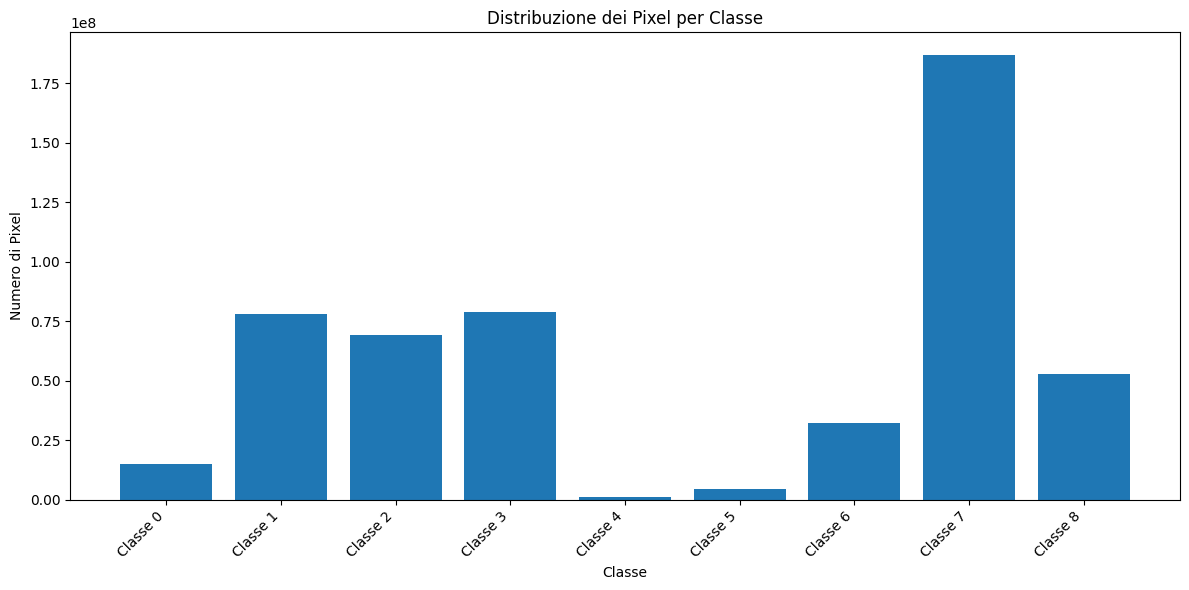

In [6]:
def calculate_class_distribution_gpu(dataset, device):
  """
  Calcola il numero di pixel per ogni classe, usando la GPU se disponibile.
  """
  num_classes = 9 # Da 0 a 8

  class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)

  loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

  for _, masks_batch in tqdm(loader, desc="Analisi distribuzione classi (GPU)"):
    masks_batch = masks_batch.to(device)

    for i in range(masks_batch.shape[0]):
      mask = masks_batch[i]
      class_counts += torch.bincount(mask.flatten(), minlength=num_classes)

  # sulla CPU per NumPy e Matplotlib
  return class_counts.cpu()


def distribution_analysis(full_dataset, class_names):
  # Calcoliamo la distribuzione
  distribution = calculate_class_distribution_gpu(full_dataset, device)

  # Stampiamo e visualizziamo i risultati
  total_pixels = distribution.sum()
  print("\nDistribuzione delle classi nel dataset:")
  for i, count in enumerate(distribution):
    percentage = 100 * count.float() / total_pixels
    print(f"- Classe '{class_names[i]}' ({i}): {count} pixel ({percentage:.2f}%)")

  plt.figure(figsize=(12, 6))
  plt.bar(class_names, distribution.numpy())
  plt.xlabel("Classe")
  plt.ylabel("Numero di Pixel")
  plt.title("Distribuzione dei Pixel per Classe")
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()


if not EXECUTE_MAIN:
  # Creiamo un dataset con tutti i campioni ...
  all_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
  # ... senza __MACOSX
  all_sample_dirs = [d for d in all_sample_dirs if not os.path.basename(d).startswith('__')]
  print(f"Trovati {len(all_sample_dirs)} campioni totali validi.")

  full_dataset = SegmentationDataset(sample_dirs=all_sample_dirs)

  class_names = []
  for idx in range(9):
    class_names.append(f"Classe {idx}")

  distribution_analysis(full_dataset, class_names)

In [7]:
import torch
from tqdm import tqdm
import os

def get_representative_images_per_class(dataset, num_classes, class_names, top_n=5):
    """
    Analizza il dataset per trovare le 'top_n' immagini più rappresentative per ogni classe.

    Args:
        dataset (Dataset): L'istanza del dataset completo.
        num_classes (int): Il numero di classi totali.
        class_names (list): La lista dei nomi delle classi.
        top_n (int): Il numero di immagini da mostrare per ogni classe.
    """
    print(f"Inizio analisi per trovare le {top_n} immagini più rappresentative per classe...")

    class_images = [[] for _ in range(num_classes)]

    for i in tqdm(range(len(dataset)), desc="Analisi Immagini"):
        _, mask = dataset[i]
        total_pixels_in_mask = mask.numel()
        if total_pixels_in_mask == 0:
            continue
        counts = torch.bincount(mask.flatten(), minlength=num_classes)
        for class_id in range(num_classes):
            if counts[class_id] > 0:
                percentage = 100.0 * counts[class_id] / total_pixels_in_mask
                sample_path = dataset.sample_dirs[i]
                class_images[class_id].append((percentage, sample_path))

    print("\nAnalisi completata. Ordino e stampo i risultati...")

    # Ordinamento e Stampa
    for class_id in range(num_classes):
        print("-" * 50)
        print(f"CLASSE: {class_names[class_id].upper()} ({class_id})")
        print("-" * 50)

        sorted_images = sorted(class_images[class_id], key=lambda x: x[0], reverse=True)

        if not sorted_images:
            print("Nessuna immagine trovata per questa classe.")
            continue

        # Stampa solo i primi 'top_n' elementi
        for idx, (percentage, path) in enumerate(sorted_images[:top_n]):
            print(f"{idx + 1}. {os.path.basename(path)} (presenza: {percentage:.2f}%)")



print("--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---")
get_representative_images_per_class(full_dataset, num_classes=9, class_names=class_names, top_n=1)



--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---
Inizio analisi per trovare le 1 immagini più rappresentative per classe...


Analisi Immagini: 100%|██████████| 931/931 [00:11<00:00, 80.13it/s]



Analisi completata. Ordino e stampo i risultati...
--------------------------------------------------
CLASSE: CLASSE 0 (0)
--------------------------------------------------
1. 0546 (presenza: 44.05%)
--------------------------------------------------
CLASSE: CLASSE 1 (1)
--------------------------------------------------
1. 0312 (presenza: 66.15%)
--------------------------------------------------
CLASSE: CLASSE 2 (2)
--------------------------------------------------
1. 0833 (presenza: 73.56%)
--------------------------------------------------
CLASSE: CLASSE 3 (3)
--------------------------------------------------
1. 1147 (presenza: 66.82%)
--------------------------------------------------
CLASSE: CLASSE 4 (4)
--------------------------------------------------
1. 0305 (presenza: 19.65%)
--------------------------------------------------
CLASSE: CLASSE 5 (5)
--------------------------------------------------
1. 0531 (presenza: 39.47%)
------------------------------------------------

In [13]:
# %%
# ==============================================================================
# 5. DATA AUGMENTATION OFFLINE (VERSIONE 5 - MAPPING COLORI CORRETTO)
# ==============================================================================
#
# OBIETTIVO:
# Risolvere il problema di mapping dei colori. Invece di generare una nuova
# palette, estraiamo la palette direttamente dal file della maschera originale
# e la riapplichiamo alla nuova maschera aumentata. Questo garantisce una
# corrispondenza di colori 1:1.

import os
import numpy as np
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tqdm import tqdm
import shutil

# La funzione create_color_palette è stata rimossa perché era la fonte dell'errore.

def create_focused_mask(
    mask: np.ndarray,
    target_class: int,
    distance_threshold: int = 30,
    ignore_index: int = 0
) -> np.ndarray:
    """Genera una maschera focalizzata (invariata)."""
    new_mask = mask.copy()
    target_pixels = (mask == target_class)
    if not np.any(target_pixels):
        return mask
    distances = distance_transform_edt(~target_pixels)
    keep_mask = distances <= distance_threshold
    new_mask[~keep_mask] = ignore_index
    return new_mask

def generate_and_save_augmented_data_v5(
    dataset: Dataset,
    classes_to_augment: dict,
    base_path: str
):
    """
    Genera campioni aumentati estraendo e riapplicando la palette originale.
    """
    if os.path.exists(base_path):
        print(f"La cartella di augmentation '{base_path}' esiste già. La svuoto.")
        shutil.rmtree(base_path)
    os.makedirs(base_path, exist_ok=True)
    print(f"Creata cartella per l'augmentation: '{base_path}'")

    augmented_sample_counter = 0

    for i in tqdm(range(len(dataset)), desc="Generazione dati (mapping corretto)"):
        original_sample_path = dataset.sample_dirs[i]
        original_sample_id = os.path.basename(original_sample_path)
        
        # --- ESTRAZIONE PALETTE ORIGINALE ---
        # Carichiamo la maschera originale con PIL per accedere alla sua palette
        original_mask_path = os.path.join(original_sample_path, 'labels.png')
        try:
            original_mask_pil = Image.open(original_mask_path)
            # Estraiamo la palette se l'immagine è in modalità 'P' (Paletted)
            original_palette = original_mask_pil.getpalette()
            if original_palette is None:
                print(f"Attenzione: la maschera {original_sample_id} non ha una palette. Salto.")
                continue
        except Exception as e:
            print(f"Errore nel caricare la maschera {original_sample_id}: {e}")
            continue
        # ------------------------------------

        # Otteniamo i dati della maschera come array per la manipolazione
        mask_np = np.array(original_mask_pil)

        for class_id, threshold in classes_to_augment.items():
            if np.any(mask_np == class_id):
                focused_mask_np = create_focused_mask(
                    mask=mask_np,
                    target_class=class_id,
                    distance_threshold=threshold
                )

                new_sample_name = f"{original_sample_id}_aug_class{class_id}"
                new_sample_dir = os.path.join(base_path, new_sample_name)
                os.makedirs(new_sample_dir, exist_ok=True)
                
                # --- APPLICAZIONE PALETTE E SALVATAGGIO ---
                mask_img = Image.fromarray(focused_mask_np.astype(np.uint8), mode='P')
                mask_img.putpalette(original_palette) # Applichiamo la palette estratta
                mask_save_path = os.path.join(new_sample_dir, 'labels.png')
                mask_img.save(mask_save_path)
                
                # Copia l'immagine RGB originale (più efficiente che ricaricarla)
                original_img_path = os.path.join(original_sample_path, 'rgb.jpg')
                new_img_path = os.path.join(new_sample_dir, 'rgb.jpg')
                shutil.copy(original_img_path, new_img_path)
                
                augmented_sample_counter += 1

    print("-" * 50)
    print(f"Processo di augmentation completato.")
    print(f"Creati {augmented_sample_counter} nuovi campioni in '{base_path}'")
    print("Il mapping dei colori ora è garantito essere identico a quello originale.")
    print("-" * 50)


# --- ESECUZIONE DELLA PIPELINE DI AUGMENTATION ---

AUGMENTED_DATASET_PATH = "../../dataset/training/augmented"
CLASSES_TO_AUGMENT = {
    4: 40,
    5: 25,
    6: 30, # La classe degli ostacoli rossi
}

if 'full_dataset' in locals() and hasattr(full_dataset, 'sample_dirs'):
    generate_and_save_augmented_data_v5(
        dataset=full_dataset,
        classes_to_augment=CLASSES_TO_AUGMENT,
        base_path=AUGMENTED_DATASET_PATH
    )
else:
    print("ERRORE: l'oggetto 'full_dataset' non è definito o non è del tipo corretto.")

Creata cartella per l'augmentation: '../../dataset/training/augmented'


Generazione dati (mapping corretto): 100%|██████████| 931/931 [00:18<00:00, 51.40it/s] 

--------------------------------------------------
Processo di augmentation completato.
Creati 561 nuovi campioni in '../../dataset/training/augmented'
Il mapping dei colori ora è garantito essere identico a quello originale.
--------------------------------------------------


ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE
Trovati 931 campioni originali.


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:13<00:00,  1.10it/s]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


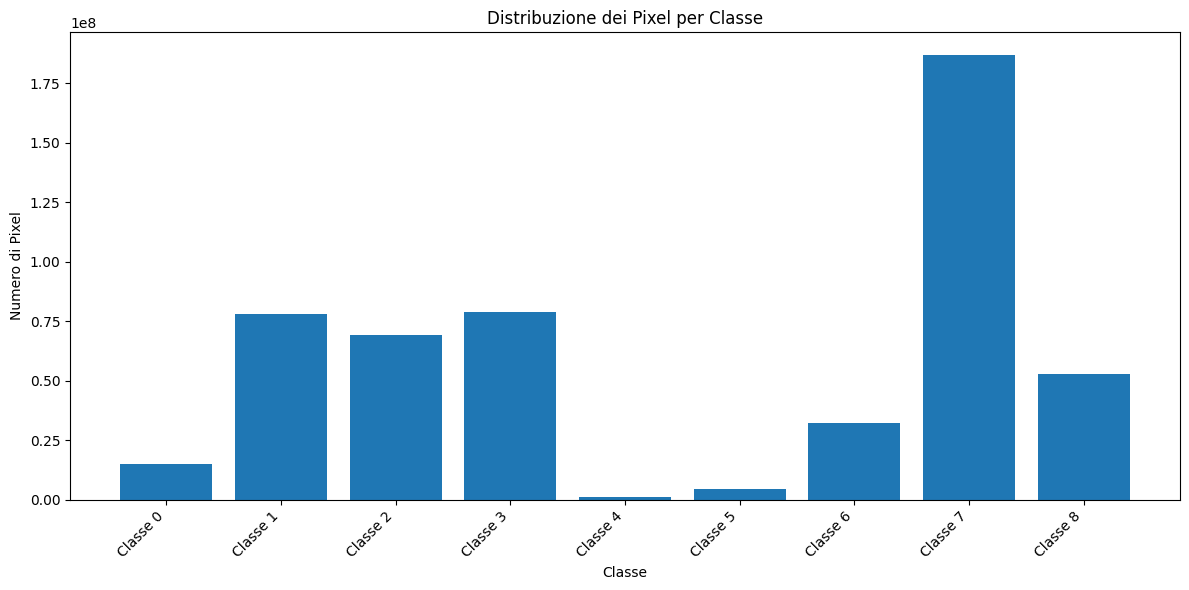





ANALISI 2: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + AUMENTATO)
Dataset originale: 931 campioni
Dataset aumentato: 561 campioni
Dataset di training finale: 1492 campioni totali


Analisi distribuzione classi (GPU): 100%|██████████| 24/24 [00:42<00:00,  1.75s/it]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 270463871 pixel (32.54%)
- Classe 'Classe 1' (1): 81934610 pixel (9.86%)
- Classe 'Classe 2' (2): 71448757 pixel (8.60%)
- Classe 'Classe 3' (3): 81916213 pixel (9.86%)
- Classe 'Classe 4' (4): 1964021 pixel (0.24%)
- Classe 'Classe 5' (5): 9102735 pixel (1.10%)
- Classe 'Classe 6' (6): 64927679 pixel (7.81%)
- Classe 'Classe 7' (7): 195561739 pixel (23.53%)
- Classe 'Classe 8' (8): 53807927 pixel (6.47%)


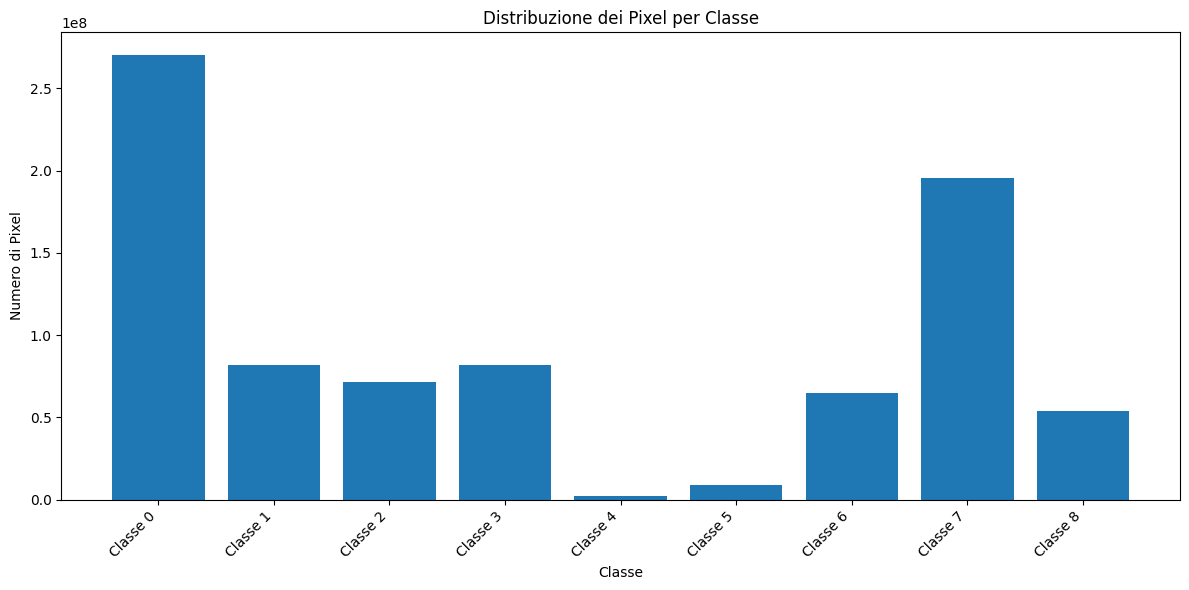

In [14]:
# %%
# ==============================================================================
# 6. ANALISI DELLA DISTRIBUZIONE POST-AUGMENTATION
# ==============================================================================
#
# OBIETTIVO:
# Verificare l'effetto della nostra data augmentation sulla distribuzione globale
# dei pixel. Ci aspettiamo di vedere un aumento significativo per le classi
# che abbiamo aumentato (4, 5, 6) e per la classe 'ignore' (0), che ora
# popola le aree irrilevanti delle maschere aumentate.

import glob
import os
import matplotlib.pyplot as plt

# Assicuriamoci che la funzione `distribution_analysis` e la classe
# `SegmentationDataset` siano definite nelle celle precedenti.

# --- 1. Analisi del dataset ORIGINALE (come baseline) ---

print("="*60)
print("ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE")
print("="*60)

# Percorsi originali (già definiti in una cella precedente)
original_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
original_sample_dirs = [d for d in original_sample_dirs if not os.path.basename(d).startswith('__')]
print(f"Trovati {len(original_sample_dirs)} campioni originali.")

original_dataset = SegmentationDataset(sample_dirs=original_sample_dirs)

# Definiamo i nomi delle classi per i grafici
class_names = [f"Classe {i}" for i in range(9)]
# Nomi più descrittivi per una migliore leggibilità
class_names_descriptive = [
    "0 (Ignore/BG)", "1 (Sky)", "2 (Rough Trail)", "3 (Smooth Trail)",
    "4 (Traversable Grass)", "5 (High Vegetation)", "6 (Low Vegetation)",
    "7 (Puddle)", "8 (Obstacle)"
]
# NOTA: La mappatura dei nomi descrittivi potrebbe non essere esatta,
# adattala in base alla documentazione del tuo dataset.
# Usiamo i nomi semplici per coerenza con il tuo codice.

distribution_analysis(original_dataset, class_names)


# --- 2. Analisi del dataset FINALE (ORIGINALE + AUMENTATO) ---

print("\n" * 3)
print("="*60)
print("ANALISI 2: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + AUMENTATO)")
print("="*60)

# Percorsi dei dati aumentati
augmented_sample_dirs = sorted([d for d in glob.glob(os.path.join(AUGMENTED_DATASET_PATH, "*")) if os.path.isdir(d)])

# Uniamo le due liste di percorsi per creare il dataset finale
final_training_dirs = original_sample_dirs + augmented_sample_dirs

print(f"Dataset originale: {len(original_sample_dirs)} campioni")
print(f"Dataset aumentato: {len(augmented_sample_dirs)} campioni")
print(f"Dataset di training finale: {len(final_training_dirs)} campioni totali")

# Creiamo l'istanza del dataset finale
final_dataset = SegmentationDataset(sample_dirs=final_training_dirs)

# Eseguiamo l'analisi della distribuzione sul dataset combinato
distribution_analysis(final_dataset, class_names)